# Лабораторная работа 5 - Перцептрон Розенблатта

Сгенерировать обучающий набор данных: ряд $y_t = f(t) + \varepsilon_t$.

Вариант 2, $N = 500$:

- $f(t) = 0.03t - 5$ - линейный тренд
- $\varepsilon_t$ - шум, распределение Лапласа с $b = 0.3$
- размер окна: 6

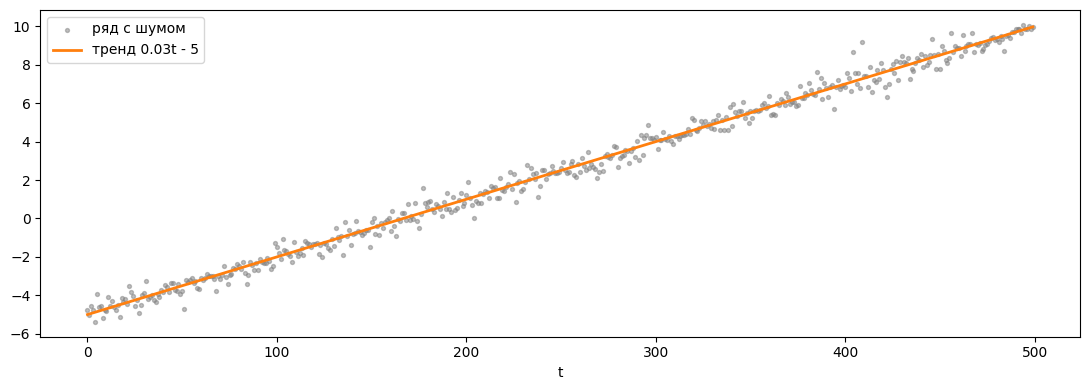

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

N = 500
WINDOW = 6

t = np.arange(N)
trend = 0.03 * t - 5
series = trend + rng.laplace(0, 0.3, N)

plt.figure(figsize=(11, 4))
plt.scatter(t, series, s=8, alpha=0.5, color="gray", label="ряд с шумом")
plt.plot(t, trend, color="tab:orange", linewidth=2, label="тренд 0.03t - 5")
plt.xlabel("t")
plt.legend()
plt.tight_layout()
plt.show()

Превратить ряд в таблицу: вход - окно из 6 предыдущих значений, цель - следующее значение

$$x_t = (y_{t-6},\ y_{t-5},\ \dots,\ y_{t-1}) \quad\to\quad y_t$$

In [2]:
def make_windows(series, size):
    X = np.array([series[i - size:i] for i in range(size, len(series))])
    y = series[size:]
    return X, y

X, y = make_windows(series, WINDOW)
t_y = t[WINDOW:]

df = pd.DataFrame(X, columns=[f"y(t-{k})" for k in range(WINDOW, 0, -1)])
df["y(t)"] = y
df.head().round(3)

,y(t-6),y(t-5),y(t-4),y(t-3),y(t-2),y(t-1),y(t)
0,-4.762,-5.009,-4.561,-4.759,-5.381,-3.944,-4.598
1,-5.009,-4.561,-4.759,-5.381,-3.944,-4.598,-4.535
2,-4.561,-4.759,-5.381,-3.944,-4.598,-4.535,-5.169
3,-4.759,-5.381,-3.944,-4.598,-4.535,-5.169,-4.761
4,-5.381,-3.944,-4.598,-4.535,-5.169,-4.761,-4.790


Разделить выборку на train/test (80% / 20%) по времени и нормализовать входные данные

Среднее и отклонение считаем только по train:

$$z = \frac{x - \mu_{train}}{\sigma_{train}}$$

In [3]:
split = int(0.8 * N)
train = t_y < split

X_train, X_test = X[train], X[~train]
y_train, y_test = y[train], y[~train]
t_train, t_test = t_y[train], t_y[~train]

mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)
Z_train = (X_train - mu) / sigma
Z_test = (X_test - mu) / sigma

print("train:", X_train.shape, "test:", X_test.shape)
print("mu:", mu.round(3))
print("sigma:", sigma.round(3))

train: (394, 6) test: (100, 6)
mu: [0.89  0.917 0.947 0.977 1.006 1.037]
sigma: [3.447 3.444 3.443 3.447 3.447 3.444]


Реализовать перцептрон: один входной слой, один выход, линейная активация. Вычисление предсказаний и ошибки

$$\hat{y} = w_1 z_1 + w_2 z_2 + \dots + w_6 z_6 + b$$

$$MSE = \frac{1}{n}\sum (y_i - \hat{y}_i)^2, \qquad MAPE = \frac{100\%}{n}\sum \left|\frac{y_i - \hat{y}_i}{y_i}\right|$$

In [4]:
def predict(Z, w, b):
    return Z @ w + b

def mse(y, y_pred):
    return np.mean((y - y_pred) ** 2)

def mape(y, y_pred):
    return 100 * np.mean(np.abs((y - y_pred) / y))

Инициализация весов случайными значениями и обновление весов по дельта-правилу

Для каждого примера по очереди:

$$e = y - \hat{y}, \qquad w \leftarrow w + \eta\, e\, z, \qquad b \leftarrow b + \eta\, e$$

Эпоха - один проход по всем примерам train в случайном порядке.

In [5]:
def fit(Z, y, lr, epochs, seed=0):
    rng = np.random.default_rng(seed)
    w = rng.normal(0, 0.1, Z.shape[1])
    b = rng.normal(0, 0.1)
    history = [(w, b)]
    for _ in range(epochs):
        for i in rng.permutation(len(Z)):
            e = y[i] - predict(Z[i], w, b)
            w = w + lr * e * Z[i]
            b = b + lr * e
        history.append((w, b))
    return w, b, history

def metrics(history):
    rows = []
    for w, b in history:
        p_train = predict(Z_train, w, b)
        p_test = predict(Z_test, w, b)
        rows.append([mse(y_train, p_train), mse(y_test, p_test), mape(y_train, p_train), mape(y_test, p_test)])
    return pd.DataFrame(rows, columns=["MSE train", "MSE test", "MAPE train", "MAPE test"])

LR = 0.001
EPOCHS = 50

w, b, history = fit(Z_train, y_train, LR, EPOCHS)
scores = metrics(history)

print("w:", w.round(3))
print("b:", round(b, 3))
scores.iloc[[0, 1, 2, 5, 10, 20, 50]].round(3)

w: [0.534 0.518 0.667 0.523 0.571 0.635]
b: 1.066


,MSE train,MSE test,MAPE train,MAPE test
0,12.379,68.585,144.381,97.006
1,0.653,1.956,394.115,15.254
2,0.344,0.483,355.284,6.706
5,0.179,0.259,238.964,4.672
10,0.163,0.238,197.375,4.396
20,0.162,0.237,189.647,4.383
50,0.162,0.237,190.085,4.381


Построить график зависимости истинных и предсказанных значений

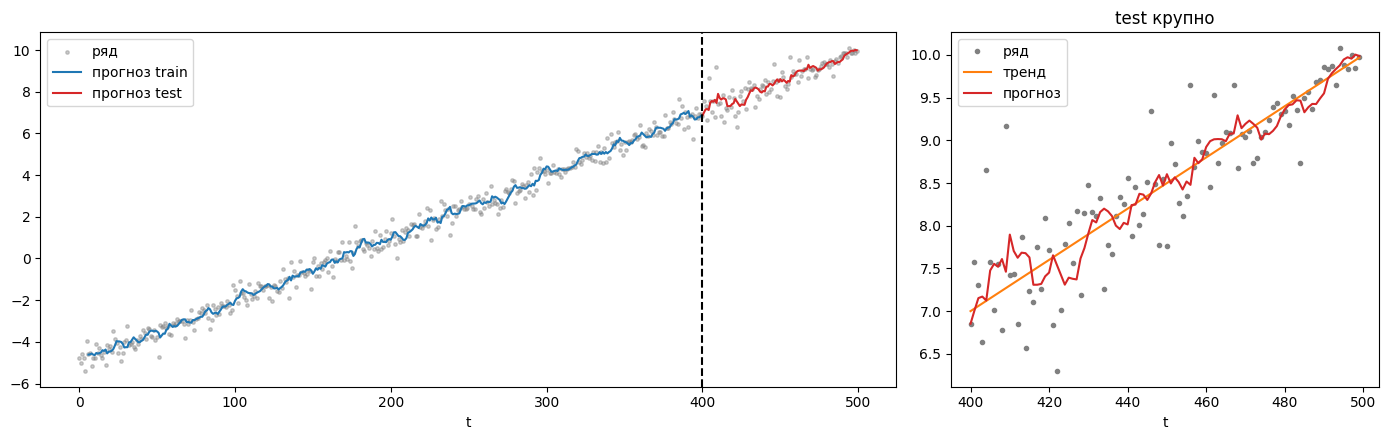

In [6]:
pred_train = predict(Z_train, w, b)
pred_test = predict(Z_test, w, b)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})

axes[0].scatter(t, series, s=6, alpha=0.4, color="gray", label="ряд")
axes[0].plot(t_train, pred_train, color="tab:blue", label="прогноз train")
axes[0].plot(t_test, pred_test, color="tab:red", label="прогноз test")
axes[0].axvline(split, color="black", linestyle="--")
axes[0].set_xlabel("t")
axes[0].legend()

axes[1].plot(t_test, y_test, "o", markersize=3, color="gray", label="ряд")
axes[1].plot(t_test, trend[t_test], color="tab:orange", label="тренд")
axes[1].plot(t_test, pred_test, color="tab:red", label="прогноз")
axes[1].set_xlabel("t")
axes[1].set_title("test крупно")
axes[1].legend()

plt.tight_layout()
plt.show()

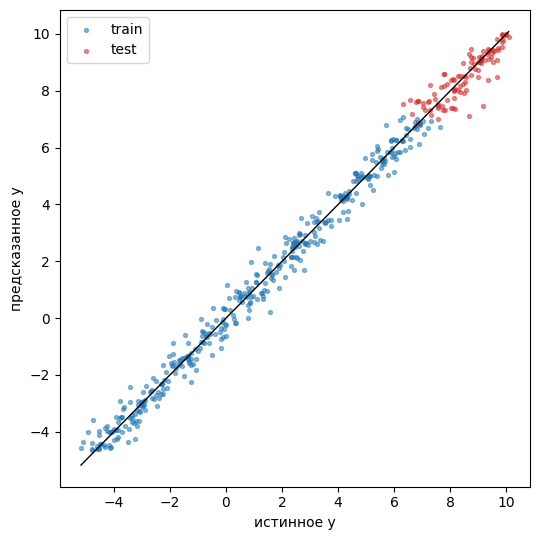

In [7]:
lims = [y.min(), y.max()]

plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_train, pred_train, s=8, alpha=0.5, label="train")
plt.scatter(y_test, pred_test, s=8, alpha=0.5, color="tab:red", label="test")
plt.plot(lims, lims, color="black", linewidth=1)
plt.xlabel("истинное y")
plt.ylabel("предсказанное y")
plt.legend()
plt.tight_layout()
plt.show()

Построить график MSE и MAPE по эпохам для train и test

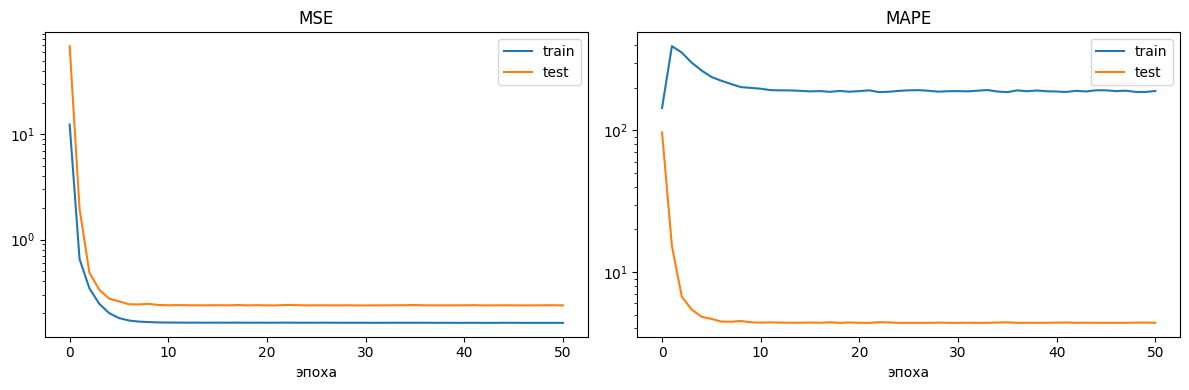

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, name in zip(axes, ["MSE", "MAPE"]):
    ax.plot(scores[f"{name} train"], label="train")
    ax.plot(scores[f"{name} test"], label="test")
    ax.set_yscale("log")
    ax.set_xlabel("эпоха")
    ax.set_title(name)
    ax.legend()

plt.tight_layout()
plt.show()

Визуально оценить, насколько хорошо модель аппроксимирует функцию

Сравним с точным решением МНК из лабы 3 и с простым прогнозом «следующее значение равно последнему в окне». Дисперсия шума Лапласа равна $2b^2 = 0.18$: меньше этого ошибка на новых данных быть не может.

In [9]:
A_train = np.c_[Z_train, np.ones(len(Z_train))]
coef = np.linalg.lstsq(A_train, y_train, rcond=None)[0]
w_mnk, b_mnk = coef[:-1], coef[-1]

def row(p_train, p_test):
    return [mse(y_train, p_train), mse(y_test, p_test), mape(y_train, p_train), mape(y_test, p_test)]

pd.DataFrame({
    "дельта-правило": row(pred_train, pred_test),
    "МНК": row(predict(Z_train, w_mnk, b_mnk), predict(Z_test, w_mnk, b_mnk)),
    "последнее значение": row(X_train[:, -1], X_test[:, -1]),
}, index=["MSE train", "MSE test", "MAPE train", "MAPE test"]).round(3)

,дельта-правило,МНК,последнее значение
MSE train,0.162,0.159,0.265
MSE test,0.237,0.240,0.422
MAPE train,190.085,184.998,93.501
MAPE test,4.381,4.441,5.912


In [10]:
w_orig = w / sigma
b_orig = b - np.sum(w * mu / sigma)

print("веса в исходных единицах:", w_orig.round(3))
print("сумма весов:", round(w_orig.sum(), 3))
print("смещение:", round(b_orig, 3))
print("веса МНК:", (w_mnk / sigma).round(3))
print("наименьшее |y| в train:", round(np.abs(y_train).min(), 4), "в test:", round(np.abs(y_test).min(), 4))

веса в исходных единицах: [0.155 0.15  0.194 0.152 0.166 0.184]
сумма весов: 1.001
смещение: 0.1
веса МНК: [0.096 0.12  0.241 0.088 0.229 0.226]
наименьшее |y| в train: 0.0012 в test: 6.3032


Изменить скорость обучения и оценить её влияние на сходимость

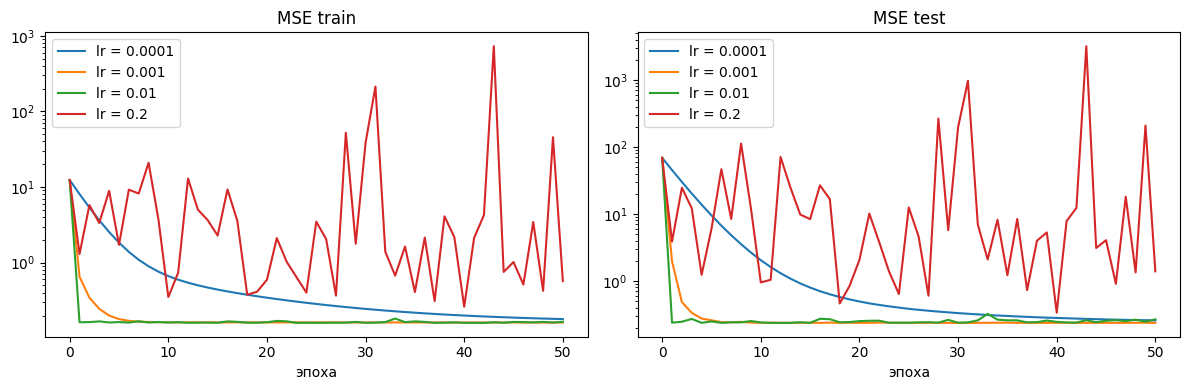

,MSE train,MSE test,MAPE train,MAPE test
0.0001,0.180,0.258,239.465,4.658
0.0010,0.162,0.237,190.085,4.381
0.0100,0.165,0.268,170.441,4.766
0.2000,0.571,1.392,343.043,11.801


In [11]:
rates = [0.0001, 0.001, 0.01, 0.2]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
final = {}

for lr in rates:
    _, _, h = fit(Z_train, y_train, lr, EPOCHS)
    s = metrics(h)
    final[lr] = s.iloc[-1]
    axes[0].plot(s["MSE train"], label=f"lr = {lr}")
    axes[1].plot(s["MSE test"], label=f"lr = {lr}")

for ax, name in zip(axes, ["MSE train", "MSE test"]):
    ax.set_yscale("log")
    ax.set_xlabel("эпоха")
    ax.set_title(name)
    ax.legend()

plt.tight_layout()
plt.show()

pd.DataFrame(final).T.round(3)

Изменить количество эпох

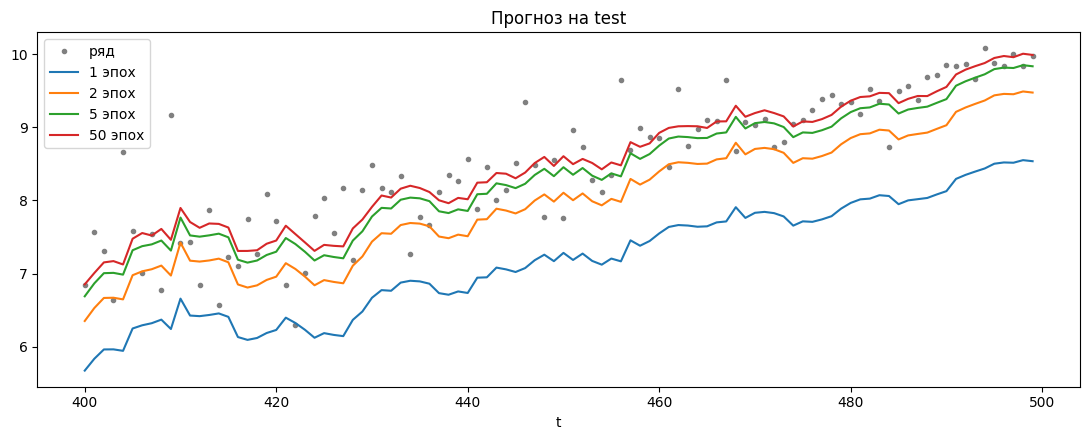

,MSE train,MSE test,MAPE train,MAPE test
1,0.653,1.956,394.115,15.254
2,0.344,0.483,355.284,6.706
5,0.179,0.259,238.964,4.672
50,0.162,0.237,190.085,4.381


In [12]:
epoch_counts = [1, 2, 5, 50]

plt.figure(figsize=(11, 4.5))
plt.plot(t_test, y_test, "o", markersize=3, color="gray", label="ряд")
final = {}

for epochs in epoch_counts:
    w_e, b_e, h = fit(Z_train, y_train, LR, epochs)
    final[epochs] = metrics(h).iloc[-1]
    plt.plot(t_test, predict(Z_test, w_e, b_e), label=f"{epochs} эпох")

plt.xlabel("t")
plt.title("Прогноз на test")
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(final).T.round(3)

Вопрос 2. Зачем нормализация: тот же ряд, записанный в сотых долях (все значения умножены на 100)

Обучаем 3 эпохи с $\eta = 0.001$ и смотрим MSE после каждой эпохи. Для ряда x100 делим MSE на $100^2$, чтобы вернуться к исходным единицам.

In [13]:
def mse_by_epoch(Z, y, scale):
    with np.errstate(all="ignore"):
        _, _, h = fit(Z, y * scale, LR, 3)
        return [mse(y * scale, predict(Z, w_, b_)) / scale ** 2 for w_, b_ in h]

pd.DataFrame({
    "без нормализации": mse_by_epoch(X_train, y_train, 1),
    "без нормализации, x100": mse_by_epoch(X_train * 100, y_train, 100),
    "с нормализацией": mse_by_epoch(Z_train, y_train, 1),
    "с нормализацией, x100": mse_by_epoch(Z_train, y_train, 100),
}).rename_axis("эпоха").round(3)

,без нормализации,"без нормализации, x100",с нормализацией,"с нормализацией, x100"
эпоха,,,,
0,11.376,11.62,12.379,13.015
1,0.163,NaN,0.653,0.772
2,0.164,NaN,0.344,0.397
3,0.168,NaN,0.245,0.269


Вопросы 1 и 5. Переобучение: меняем размер окна

Чем длиннее окно, тем больше весов. Дельта-правило сходится к решению МНК, поэтому для скорости берём его сразу.

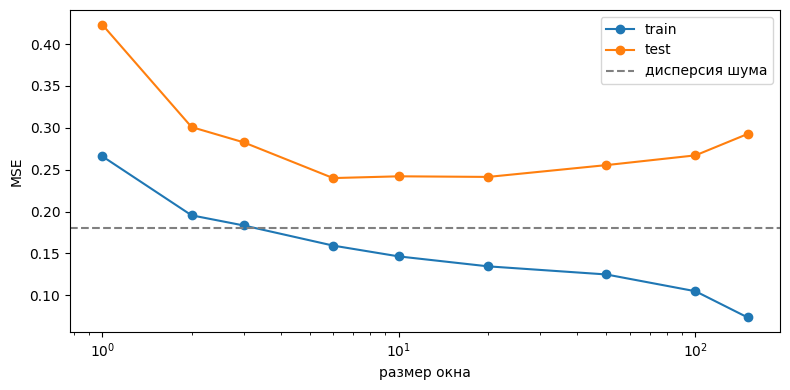

,MSE train,MSE test
1,0.2660,0.4231
2,0.1956,0.3009
3,0.1834,0.2826
6,0.1594,0.2400
10,0.1465,0.2421
20,0.1347,0.2414
50,0.1250,0.2555
100,0.1049,0.2671
150,0.0736,0.2927


In [14]:
def window_errors(size):
    X, y = make_windows(series, size)
    train = t[size:] < split
    A = np.c_[X, np.ones(len(X))]
    coef = np.linalg.lstsq(A[train], y[train], rcond=None)[0]
    return mse(y[train], A[train] @ coef), mse(y[~train], A[~train] @ coef)

sizes = [1, 2, 3, 6, 10, 20, 50, 100, 150]
errors = pd.DataFrame([window_errors(s) for s in sizes], index=sizes, columns=["MSE train", "MSE test"])

plt.figure(figsize=(8, 4))
plt.plot(sizes, errors["MSE train"], "o-", label="train")
plt.plot(sizes, errors["MSE test"], "o-", label="test")
plt.axhline(0.18, color="gray", linestyle="--", label="дисперсия шума")
plt.xscale("log")
plt.xlabel("размер окна")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.show()

errors.round(4)